# EMG gesture classifier: 1D CNN on standard EMG features, float32 vs int8

Data: the train / val / test split made by `DataAquisitionNoCamera/tools/split_dataset.py` from
the two guided sessions of 2026-11-04 (`TEST2_S2_2026-11-04_1854`, `TEST3_S2_2026-11-04_1920`).
The split is by whole trial, so no movement appears in two splits.

Pipeline:
1. **Filter** each trial with causal filters (band-pass 20-110 Hz, notch 50 and 100 Hz), the
   same kind of filter that can run sample by sample on the microcontroller.
2. **Frames**: 32 samples (128 ms) every 16 samples (64 ms). For every frame and channel, the
   five standard time-domain EMG features: MAV, RMS, WL (waveform length), ZC (zero crossings)
   and SSC (slope sign changes).
3. **Input of the CNN**: 8 consecutive frames (576 ms of signal) x 20 features (4 channels x 5).
   The 1D convolution runs along time, over the frame sequence.
4. **Classes**: REST, OPEN, CLOSE, INDEX. The cue rows (TRANSITION) and the first 0.5 s after
   every label change are left out, so the model only sees settled postures.
5. **Train** 15 epochs, batch 32. Evaluate on the test split. Then convert to TFLite float32 and
   full-integer int8 and compare size and accuracy.

In [1]:
import json
import time
from pathlib import Path

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from numpy.lib.stride_tricks import sliding_window_view
from scipy import signal
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

SPLIT_DIR = Path("../DataAquisitionNoCamera/data/splits/TEST2_S2+TEST3_S2_seed0")
OUT_DIR = Path("emg_cnn")                 # exported models and feature parameters
OUT_DIR.mkdir(exist_ok=True)

manifest = json.loads((SPLIT_DIR / "split.json").read_text(encoding="utf-8"))
FS = float(manifest["sampling_rate_hz"])
CHANNELS = manifest["channels"]
CLASSES = ["REST", "OPEN", "CLOSE", "INDEX"]

BAND_HZ = (20.0, 110.0)          # band-pass (Nyquist is 125 Hz at 250 Hz)
NOTCH_HZ = (50.0, 100.0)         # mains and its first harmonic
FRAME_LEN = 32                   # samples per frame (128 ms)
HOP = 16                         # samples between frames (64 ms)
N_FRAMES = 8                     # frames per CNN input (576 ms of signal)
SETTLE_S = 0.5                   # skipped after every label change
THRESHOLD_UV = 5.0               # dead band of ZC and SSC (first guess, tune on more data)
FEATURES = ["MAV", "RMS", "WL", "ZC", "SSC"]

EPOCHS, BATCH_SIZE, SEED = 15, 32, 0
keras.utils.set_random_seed(SEED)
print(f"fs = {FS} Hz, channels {CHANNELS}, TensorFlow {tf.__version__}, Keras {keras.__version__}")
for name in ("train", "val", "test"):
    s = manifest["splits"][name]
    print(f"{name:<5} {s['trials']:>3} trials {s['per_gesture']}")

fs = 250.0 Hz, channels ['ch1', 'ch2', 'ch3', 'ch4'], TensorFlow 2.20.0, Keras 3.11.3
train  48 trials {'OPEN': 16, 'CLOSE': 16, 'INDEX': 16}
val    12 trials {'OPEN': 4, 'CLOSE': 4, 'INDEX': 4}
test   12 trials {'OPEN': 4, 'CLOSE': 4, 'INDEX': 4}


## 1. Load the splits and filter every trial

Each trial is a contiguous block of rows (cue, hold, rest), so it is filtered on its own. The
filter state starts at the steady state of the first sample, so the large DC offset of the raw
signal does not ring through the first frames.

train  114397 rows, 48 trials
val     28594 rows, 12 trials
test    28586 rows, 12 trials


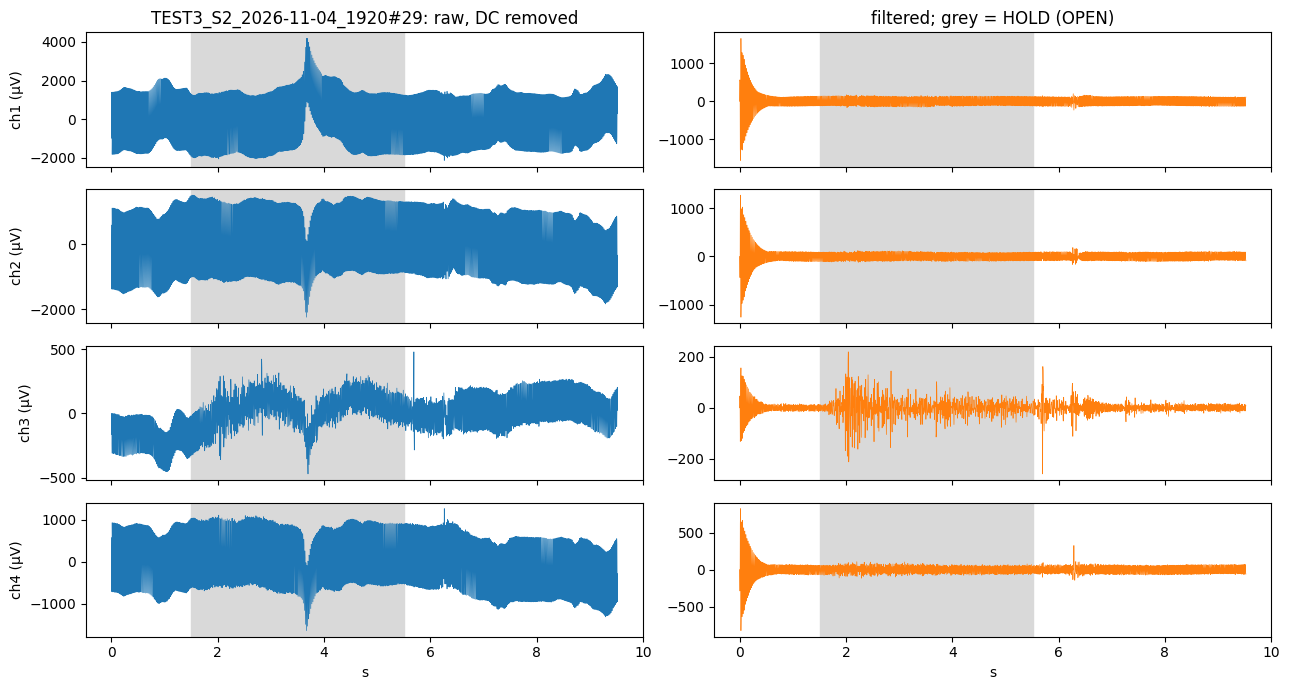

In [2]:
def make_filters(fs):
    sos = [signal.butter(4, BAND_HZ, btype="bandpass", fs=fs, output="sos")]
    for f0 in NOTCH_HZ:
        b, a = signal.iirnotch(f0, Q=30.0, fs=fs)
        sos.append(signal.tf2sos(b, a))
    return np.vstack(sos)


SOS = make_filters(FS)


def causal_filter(x):
    """x: (samples, channels) raw µV -> filtered µV, causal, started at steady state."""
    zi = signal.sosfilt_zi(SOS)[:, :, None] * x[0][None, None, :]
    y, _ = signal.sosfilt(SOS, x, axis=0, zi=zi)
    return y


splits = {name: pd.read_csv(SPLIT_DIR / f"{name}.csv", keep_default_na=False,
                            dtype={"phase": str, "label": str})
          for name in ("train", "val", "test")}
for name, df in splits.items():
    print(f"{name:<5} {len(df):>7} rows, {df['trial_uid'].nunique()} trials")

# one trial before and after filtering
uid = splits["train"]["trial_uid"].iloc[0]
tr = splits["train"][splits["train"]["trial_uid"] == uid]
raw = tr[CHANNELS].to_numpy(float)
filt = causal_filter(raw)
t = np.arange(len(tr)) / FS
fig, axes = plt.subplots(len(CHANNELS), 2, figsize=(13, 7), sharex=True)
for k, ch in enumerate(CHANNELS):
    axes[k, 0].plot(t, raw[:, k] - raw[:, k].mean(), lw=0.5)
    axes[k, 1].plot(t, filt[:, k], lw=0.5, color="C1")
    axes[k, 0].set_ylabel(f"{ch} (µV)")
hold = (tr["phase"] == "HOLD").to_numpy()
for ax in axes.ravel():
    ax.axvspan(t[hold][0], t[hold][-1], color="0.85", zorder=0)
axes[0, 0].set_title(f"{uid}: raw, DC removed")
axes[0, 1].set_title(f"filtered; grey = HOLD ({tr.loc[tr['phase'] == 'HOLD', 'label'].iloc[0]})")
axes[-1, 0].set_xlabel("s"); axes[-1, 1].set_xlabel("s")
plt.tight_layout(); plt.show()

## 2. Standard EMG features per frame

For a frame $x_1 \dots x_N$ of one channel:

| feature | definition | what it captures |
|---|---|---|
| MAV | $\frac{1}{N}\sum \lvert x_i \rvert$ | amplitude, i.e. contraction level |
| RMS | $\sqrt{\frac{1}{N}\sum x_i^2}$ | amplitude (power) |
| WL | $\sum \lvert x_{i+1}-x_i \rvert$ | amplitude and frequency together |
| ZC | sign changes with $\lvert x_{i+1}-x_i \rvert \ge T$ | frequency content |
| SSC | slope changes with $(x_i-x_{i-1})(x_i-x_{i+1}) \ge T^2$ | frequency content |

The threshold $T$ keeps noise from counting as crossings. Amplitude features are log-scaled,
because EMG amplitude spans orders of magnitude between rest and a strong grip. ZC and SSC are
divided by the frame length. All features are then standardised with the train mean and SD.

A frame gets a label only if all its samples carry the same label and at least `SETTLE_S` have
passed since the last label change. A CNN input is 8 consecutive labelled frames of one label.

In [3]:
def frame_features(frames):
    """frames: (n, channels, FRAME_LEN) filtered µV -> (n, channels * 5), channel-major."""
    d = np.diff(frames, axis=-1)
    mav = np.abs(frames).mean(-1)
    rms = np.sqrt((frames ** 2).mean(-1))
    wl = np.abs(d).sum(-1)
    zc = ((frames[..., :-1] * frames[..., 1:] < 0) & (np.abs(d) >= THRESHOLD_UV)).sum(-1)
    ssc = ((d[..., :-1] * -d[..., 1:]) >= THRESHOLD_UV ** 2).sum(-1)
    feats = np.stack([np.log1p(mav), np.log1p(rms), np.log1p(wl),
                      zc / FRAME_LEN, ssc / FRAME_LEN], axis=-1)      # (n, channels, 5)
    return feats.reshape(len(frames), -1)


def trial_frames(tr):
    """Features and labels of the frames of one trial (label None = not usable)."""
    x = causal_filter(tr[CHANNELS].to_numpy(float))
    labels = tr["label"].to_numpy()
    change = np.r_[0, np.flatnonzero(labels[1:] != labels[:-1]) + 1]
    since = np.arange(len(labels)) - change[np.searchsorted(change, np.arange(len(labels)), "right") - 1]
    frames = sliding_window_view(x, FRAME_LEN, axis=0)[::HOP]          # (n, channels, FRAME_LEN)
    starts = np.arange(len(frames)) * HOP
    out_labels = []
    for s0 in starts:
        lab = labels[s0:s0 + FRAME_LEN]
        ok = (lab == lab[0]).all() and lab[0] in CLASSES and since[s0] >= SETTLE_S * FS
        out_labels.append(lab[0] if ok else None)
    return frame_features(frames), np.array(out_labels, dtype=object)


def make_windows(df):
    """CNN inputs (n, N_FRAMES, features), class index (n,), trial uid (n,)."""
    X, y, uids = [], [], []
    for uid, tr in df.groupby("trial_uid", sort=False):
        f, lab = trial_frames(tr)
        for i in range(len(f) - N_FRAMES + 1):
            w = lab[i:i + N_FRAMES]
            if w[0] is not None and all(v == w[0] for v in w):
                X.append(f[i:i + N_FRAMES]); y.append(CLASSES.index(w[0])); uids.append(uid)
    return np.array(X, np.float32), np.array(y, np.int64), np.array(uids)


data = {name: make_windows(df) for name, df in splits.items()}
feat_names = [f"{ch}_{f}" for ch in CHANNELS for f in FEATURES]

mu = data["train"][0].reshape(-1, len(feat_names)).mean(0)
sd = data["train"][0].reshape(-1, len(feat_names)).std(0) + 1e-6
X_train, y_train, _ = data["train"]
X_val, y_val, _ = data["val"]
X_test, y_test, uid_test = data["test"]
X_train, X_val, X_test = [(X - mu) / sd for X in (X_train, X_val, X_test)]

print(f"input shape: {X_train.shape[1:]} (frames x features)")
print("windows per class:")
print(pd.DataFrame({name: np.bincount(data[name][1], minlength=len(CLASSES))
                    for name in data}, index=CLASSES).to_string())

input shape: (8, 20) (frames x features)
windows per class:
       train  val  test
REST    2208  551   552
OPEN     736  184   184
CLOSE    736  184   184
INDEX    736  184   184


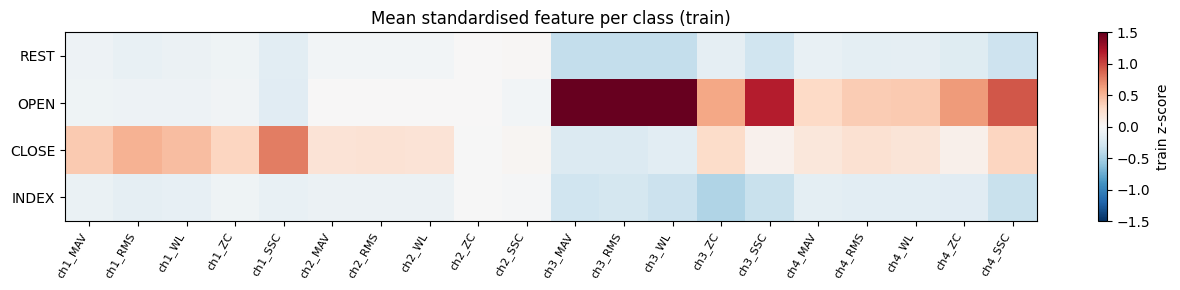

In [4]:
# mean feature value (standardised) per class on the train split
Xf = X_train.mean(axis=1)
mean_by_class = pd.DataFrame([Xf[y_train == k].mean(0) for k in range(len(CLASSES))],
                             index=CLASSES, columns=feat_names)
fig, ax = plt.subplots(figsize=(13, 3))
im = ax.imshow(mean_by_class.to_numpy(), cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
ax.set_xticks(range(len(feat_names)), feat_names, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(CLASSES)), CLASSES)
fig.colorbar(im, ax=ax, label="train z-score")
ax.set_title("Mean standardised feature per class (train)")
plt.tight_layout(); plt.show()

## 3. The 1D CNN

Small on purpose, so that it fits a microcontroller: two convolution blocks along the 8 frames,
global average pooling, one dense layer. The classes are unbalanced (REST comes from the rest
phase of every trial, about three times as much as each gesture), so the loss is weighted by
class.

In [5]:
def build_model(n_frames, n_feat, n_classes):
    inp = keras.Input((n_frames, n_feat), name="features")
    x = keras.layers.Conv1D(32, 3, padding="same", activation="relu")(inp)
    x = keras.layers.Conv1D(32, 3, padding="same", activation="relu")(x)
    x = keras.layers.MaxPooling1D(2)(x)
    x = keras.layers.Conv1D(64, 3, padding="same", activation="relu")(x)
    x = keras.layers.GlobalAveragePooling1D()(x)
    x = keras.layers.Dropout(0.3)(x)
    out = keras.layers.Dense(n_classes, activation="softmax", name="probs")(x)
    return keras.Model(inp, out, name="emg_cnn1d")


model = build_model(N_FRAMES, X_train.shape[2], len(CLASSES))
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

weights = compute_class_weight("balanced", classes=np.arange(len(CLASSES)), y=y_train)
class_weight = dict(enumerate(weights))
print("class weights:", {CLASSES[k]: round(float(w), 2) for k, w in class_weight.items()})

history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                    epochs=EPOCHS, batch_size=BATCH_SIZE, class_weight=class_weight,
                    shuffle=True, verbose=2)

Model: "emg_cnn1d"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ features (InputLayer)           │ (None, 8, 20)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 8, 32)          │         1,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 8, 32)          │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 4, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 4, 64)          │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probs (Dense)                   │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,524 (45.02 KB)

 Trainable params: 11,524 (45.02 KB)

 Non-trainable params: 0 (0.00 B)

class weights: {'REST': 0.5, 'OPEN': 1.5, 'CLOSE': 1.5, 'INDEX': 1.5}
Epoch 1/15
138/138 - 2s - 13ms/step - accuracy: 0.5315 - loss: 0.8373 - val_accuracy: 0.5458 - val_loss: 0.8216
Epoch 2/15
138/138 - 0s - 2ms/step - accuracy: 0.6014 - loss: 0.6259 - val_accuracy: 0.6691 - val_loss: 0.7816
Epoch 3/15
138/138 - 0s - 2ms/step - accuracy: 0.6553 - loss: 0.5552 - val_accuracy: 0.6791 - val_loss: 0.7433
Epoch 4/15
138/138 - 1s - 5ms/step - accuracy: 0.6868 - loss: 0.5102 - val_accuracy: 0.6854 - val_loss: 0.7349
Epoch 5/15
138/138 - 0s - 2ms/step - accuracy: 0.7208 - loss: 0.4603 - val_accuracy: 0.6782 - val_loss: 0.7431
Epoch 6/15
138/138 - 0s - 2ms/step - accuracy: 0.7405 - loss: 0.4221 - val_accuracy: 0.6818 - val_loss: 0.7419
Epoch 7/15
138/138 - 0s - 2ms/step - accuracy: 0.7661 - loss: 0.3905 - val_accuracy: 0.6836 - val_loss: 0.7821
Epoch 8/15
138/138 - 0s - 2ms/step - accuracy: 0.7794 - loss: 0.3648 - val_accuracy: 0.6754 - val_loss: 0.8088
Epoch 9/15
138/138 - 0s - 3ms/step - accu

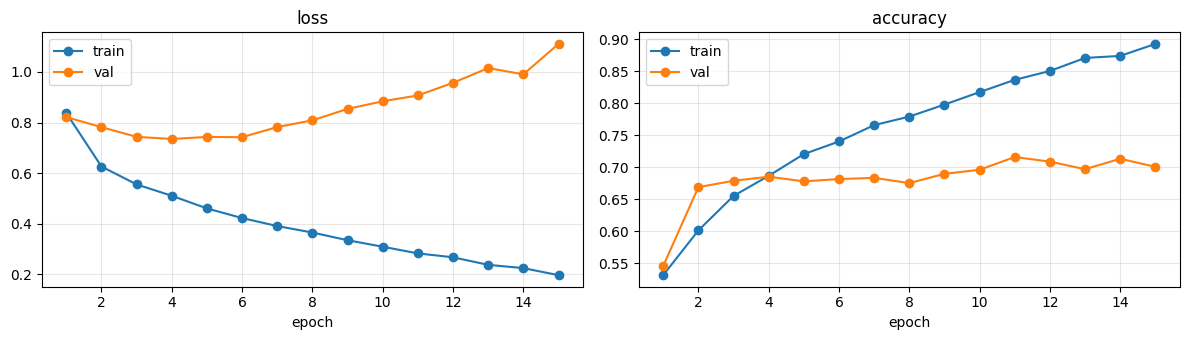

In [6]:
h = history.history
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
epochs = np.arange(1, EPOCHS + 1)
axes[0].plot(epochs, h["loss"], "o-", label="train"); axes[0].plot(epochs, h["val_loss"], "o-", label="val")
axes[1].plot(epochs, h["accuracy"], "o-", label="train"); axes[1].plot(epochs, h["val_accuracy"], "o-", label="val")
axes[0].set_title("loss"); axes[1].set_title("accuracy")
for ax in axes:
    ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

## 4. Evaluation on the test split

Window accuracy counts every 576 ms input. Trial accuracy takes the majority vote of the
windows of the HOLD part of each test trial, which is closer to "did it recognise the grip".

In [7]:
def report(name, pred):
    print(f"{name}: window accuracy {accuracy_score(y_test, pred):.3f}")
    print(classification_report(y_test, pred, labels=range(len(CLASSES)), target_names=CLASSES,
                                digits=3, zero_division=0))


def trial_accuracy(pred):
    rows = []
    for uid in np.unique(uid_test):
        m = (uid_test == uid) & (y_test != CLASSES.index("REST"))
        if m.any():
            rows.append(np.bincount(pred[m], minlength=len(CLASSES)).argmax() == y_test[m][0])
    return float(np.mean(rows)), len(rows)


def plot_confusion(pred, title, ax):
    cm = confusion_matrix(y_test, pred, labels=range(len(CLASSES)), normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                    color="white" if cm[i, j] > 0.5 else "black")
    ax.set_xticks(range(len(CLASSES)), CLASSES); ax.set_yticks(range(len(CLASSES)), CLASSES)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)


probs_keras = model.predict(X_test, batch_size=256, verbose=0)
pred_keras = probs_keras.argmax(1)
report("Keras float32", pred_keras)
acc_t, n_t = trial_accuracy(pred_keras)
print(f"trial accuracy (majority vote over the hold): {acc_t:.3f} on {n_t} trials")

Keras float32: window accuracy 0.636
              precision    recall  f1-score   support

        REST      0.667     0.676     0.671       552
        OPEN      0.822     0.951     0.882       184
       CLOSE      0.435     0.603     0.506       184
       INDEX      0.558     0.234     0.330       184

    accuracy                          0.636      1104
   macro avg      0.621     0.616     0.597      1104
weighted avg      0.636     0.636     0.622      1104

trial accuracy (majority vote over the hold): 0.583 on 12 trials


## 5. Export and quantisation

Three versions of the same network:

- **Keras** model file (float32, includes the training state)
- **TFLite float32**: the inference graph only
- **TFLite int8** (full-integer post-training quantisation): weights and activations in 8 bits.
  The scales of the activations are calibrated on a representative set of train inputs. Input
  and output are int8 too, which is what TensorFlow Lite Micro on a microcontroller expects.

The test split is run through the two TFLite models with the TFLite interpreter.

In [8]:
keras_path = OUT_DIR / "emg_cnn1d.keras"
model.save(keras_path)


def converter_for(m):
    return tf.lite.TFLiteConverter.from_keras_model(m)


conv = converter_for(model)
tfl_float = conv.convert()

rng = np.random.default_rng(SEED)
rep_idx = rng.choice(len(X_train), size=min(500, len(X_train)), replace=False)


def representative_data():
    for i in rep_idx:
        yield [X_train[i:i + 1]]


conv = converter_for(model)
conv.optimizations = [tf.lite.Optimize.DEFAULT]
conv.representative_dataset = representative_data
conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
conv.inference_input_type = tf.int8
conv.inference_output_type = tf.int8
tfl_int8 = conv.convert()

float_path, int8_path = OUT_DIR / "emg_cnn1d_float32.tflite", OUT_DIR / "emg_cnn1d_int8.tflite"
float_path.write_bytes(tfl_float)
int8_path.write_bytes(tfl_int8)

# feature parameters needed to run the model elsewhere (e.g. on the board)
(OUT_DIR / "features.json").write_text(json.dumps({
    "fs": FS, "channels": CHANNELS, "classes": CLASSES, "band_hz": BAND_HZ, "notch_hz": NOTCH_HZ,
    "frame_len": FRAME_LEN, "hop": HOP, "n_frames": N_FRAMES, "threshold_uv": THRESHOLD_UV,
    "features": FEATURES, "feature_order": feat_names,
    "amplitude_transform": "log1p (MAV, RMS, WL); ZC, SSC divided by frame_len",
    "mean": mu.tolist(), "sd": sd.tolist(), "split": str(SPLIT_DIR), "seed": SEED}, indent=2),
    encoding="utf-8")


def run_tflite(model_bytes, X):
    interp = tf.lite.Interpreter(model_content=model_bytes)
    interp.allocate_tensors()
    inp, out = interp.get_input_details()[0], interp.get_output_details()[0]
    in_scale, in_zero = inp["quantization"]
    out_scale, out_zero = out["quantization"]
    probs = np.empty((len(X), len(CLASSES)), np.float32)
    t0 = time.perf_counter()
    for i in range(len(X)):
        x = X[i:i + 1]
        if inp["dtype"] == np.int8:
            x = np.clip(np.round(x / in_scale + in_zero), -128, 127).astype(np.int8)
        interp.set_tensor(inp["index"], x)
        interp.invoke()
        y = interp.get_tensor(out["index"])[0]
        probs[i] = (y.astype(np.float32) - out_zero) * out_scale if out["dtype"] == np.int8 else y
    per_call_ms = (time.perf_counter() - t0) / len(X) * 1e3
    return probs, per_call_ms, inp, out


probs_float, ms_float, _, _ = run_tflite(tfl_float, X_test)
probs_int8, ms_int8, inp8, out8 = run_tflite(tfl_int8, X_test)
pred_float, pred_int8 = probs_float.argmax(1), probs_int8.argmax(1)
print("int8 input quantisation (scale, zero point):", inp8["quantization"])
print("int8 output quantisation (scale, zero point):", out8["quantization"])

INFO:tensorflow:Assets written to: C:\Users\Gabri\AppData\Local\Temp\tmpzdzcbcw7\assets


INFO:tensorflow:Assets written to: C:\Users\Gabri\AppData\Local\Temp\tmpzdzcbcw7\assets


Saved artifact at 'C:\Users\Gabri\AppData\Local\Temp\tmpzdzcbcw7'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 8, 20), dtype=tf.float32, name='features')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  2085034278352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2085035515280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2085035515088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2085035523920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2085035513552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2085035514896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2085034428368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2085034669072: TensorSpec(shape=(), dtype=tf.resource, name=None)
INFO:tensorflow:Assets written to: C:\Users\Gabri\AppData\Local\Temp\tmpcac6g108\assets


INFO:tensorflow:Assets written to: C:\Users\Gabri\AppData\Local\Temp\tmpcac6g108\assets


Saved artifact at 'C:\Users\Gabri\AppData\Local\Temp\tmpcac6g108'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 8, 20), dtype=tf.float32, name='features')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  2085034278352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2085035515280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2085035515088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2085035523920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2085035513552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2085035514896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2085034428368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2085034669072: TensorSpec(shape=(), dtype=tf.resource, name=None)


C:\Users\Gabri\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tensorflow\lite\python\convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


int8 input quantisation (scale, zero point): (0.06696373224258423, 1)
int8 output quantisation (scale, zero point): (0.00390625, -128)


C:\Users\Gabri\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


## 6. Size and accuracy: float32 vs int8

In [9]:
n_params = model.count_params()
rows = []
for name, size, pred, ms in (
        ("Keras file (float32)", keras_path.stat().st_size, pred_keras, None),
        ("TFLite float32", len(tfl_float), pred_float, ms_float),
        ("TFLite int8", len(tfl_int8), pred_int8, ms_int8)):
    rows.append({"model": name, "size_kB": round(size / 1024, 1),
                 "test_window_acc": round(accuracy_score(y_test, pred), 3),
                 "test_trial_acc": round(trial_accuracy(pred)[0], 3),
                 "agrees_with_keras": round(float((pred == pred_keras).mean()), 3),
                 "PC_ms_per_input": None if ms is None else round(ms, 3)})
comparison = pd.DataFrame(rows).set_index("model")
print(f"parameters: {n_params:,}  -> float32 weights {n_params * 4 / 1024:.1f} kB, "
      f"int8 weights {n_params / 1024:.1f} kB")
print(f"TFLite int8 is {len(tfl_float) / len(tfl_int8):.1f}x smaller than TFLite float32")
print(f"max |probability difference| int8 vs float32: {np.abs(probs_int8 - probs_float).max():.3f}")
comparison

parameters: 11,524  -> float32 weights 45.0 kB, int8 weights 11.3 kB
TFLite int8 is 2.4x smaller than TFLite float32
max |probability difference| int8 vs float32: 0.340


,size_kB,test_window_acc,test_trial_acc,agrees_with_keras,PC_ms_per_input
model,,,,,
Keras file (float32),174.7,0.636,0.583,1.000,NaN
TFLite float32,50.2,0.636,0.583,1.000,0.004
TFLite int8,20.7,0.639,0.500,0.981,0.010


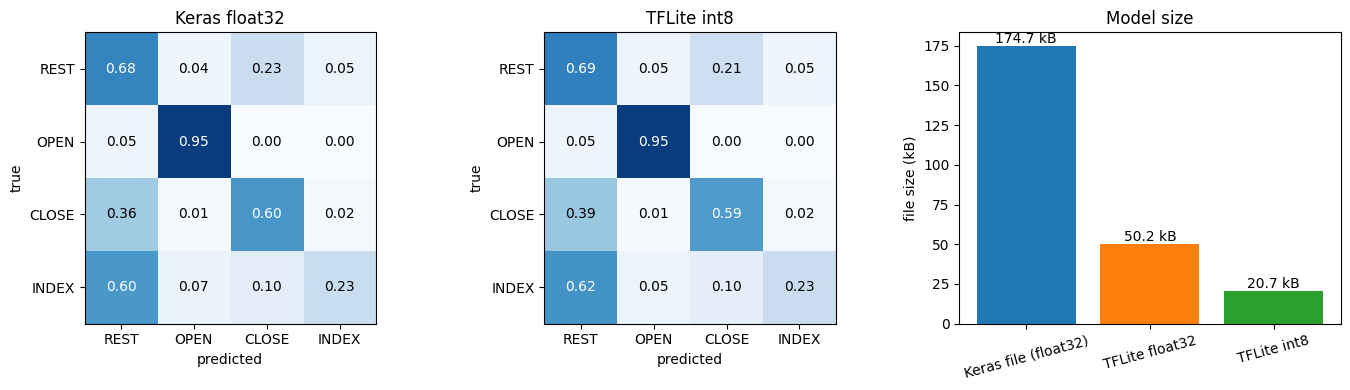

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
plot_confusion(pred_keras, "Keras float32", axes[0])
plot_confusion(pred_int8, "TFLite int8", axes[1])
names = comparison.index.tolist()
axes[2].bar(names, comparison["size_kB"], color=["C0", "C1", "C2"])
for i, v in enumerate(comparison["size_kB"]):
    axes[2].text(i, v, f"{v} kB", ha="center", va="bottom")
axes[2].set_ylabel("file size (kB)"); axes[2].set_title("Model size")
axes[2].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

## Notes

- Only two sessions of one subject on one day, and 12 test trials: the scores are a first look,
  not a performance estimate. A test on another day (electrodes placed again) will be lower.
- The PC timings only compare the two models; they say nothing about the time on the board.
- The model reads 576 ms of signal, so a decision lags the movement by up to about that much.
  `N_FRAMES`, `FRAME_LEN` and `HOP` set this trade-off.
- The feature parameters (filters, frames, mean and SD) are in `emg_cnn/features.json`; the
  board must compute exactly the same features before feeding the int8 model.